In [268]:
from random import random,randint, choice
from numpy import log
import pprint

In [269]:
#######################################
#######################################
## TIPOS DADOS A DESENVOLVER NA PARTE 1
#######################################
## incluem-se alguns comentários que esclarecem 
## alguns detalhes relevantes
####################################################

In [270]:
###################
### CLASSE CELULA
###################
### notar que vai ser apenas  necessário usar o nível trófico 
### para representar a espécie, e portanto a classe célula
### só precisa de dois atributos
####################################################



class Celula():
    def __init__(self,m,p):
        self._especie=m
        self._resiliencia=p
        
    def daEsp(self): 
            return self._especie
        
    def daRes(self): 
            return self._resiliencia
    
    ## para depuração de erros
    def mostra(self):
        return "Esp:"+str(self._especie)+" "+"Res:"+str(self._resiliencia)

In [271]:
## TESTES

c1=Celula(1,12)   

## criação de objeto da classe Célula, em que a espécie/nivel trófico é 1 
## e a resiliência é 12

In [272]:
c1.daEsp()

1

In [273]:
c1.daRes()

12

In [274]:
c1.mostra()

'Esp:1 Res:12'

In [275]:
#################
## CLASSE GRELHA
#################

In [276]:
class Grelha():
    def __init__(self, N):   
        self._N=N
        self._g={}
        
    def daN(self):     
        return self._N
    
   
    #associa uma célula (objeto da classe célula) a uma quadricula
    def associar(self,i,j,c): 
    	self._g[(i,j)]=c
     
    # remove a célula que estiver associada à quadrícula
    def remover(self,i,j):
        #ou self._g.pop((i,j),"REMOVER::nada associado a esta quadricula")
        if not self.vaziaQ(i,j):
            self._g.pop((i,j))
        else:
            return "REMOVER::nada associado a esta quadricula"

    def vaziaQ(self,i,j):
        return (i,j) not in self._g
        #ou return not((i,j) in self._g)

    def daEspecie(self,i,j): 
        if not self.vaziaQ(i,j):
            return self._g[(i,j)].daEsp()
        else:
            return "daESPECIE::nada associado a esta quadricula"
            
    def daResiliencia(self,i,j):  
        if not self.vaziaQ(i,j):
            return self._g[(i,j)].daRes()
        else:
            return "daRESILIENCIA::nada associado a esta quadricula"
        
            
    def vizinhanca(self,i,j,r):
        
        def normaliza(x):   
            if x<-self._N:
                return x+2*self._N + 1
            elif x>self._N:
                 return x-(2*self._N + 1)
            else:
                return x
            
        return [(normaliza(a+i),normaliza(b+j)) for a in range(-r,r+1) for b in range(-r,r+1)]
    

    #quadriculas ocupadas pela especie s na vizinhanca de raio r de (i,j)
    def quadsComEsp(self,i,j,r,s):
        return [(a,b) for (a,b) in self.vizinhanca(i,j,r) if (not self.vaziaQ(a,b) and self.daEspecie(a,b)==s)]

    
    #numero de quadriculas ocupadas pela especie s na vizinhanca de raio r de (i,j)
    def numQuadsComEsp(self,i,j,r,s):
        return len(self.quadsComEsp(i,j,r,s))
        
    def matriz(self):
        n=self._N
        m=[]
        for a in range(2*n+1):
                lin=[]
                for b in range(2*n+1):
                    if not self.vaziaQ(b-n,n-a):
                        lin.append(self.daEspecie(b-n,n-a))
                    else:
                        lin.append(0)
                m.append(lin)
        return m 
    
    
    ## para depuração de erros
    def mostra(self):
        listaQds=self._g.keys()
        aux=[]
        for pos in listaQds:
            aux.append((pos,self._g[pos].mostra()))
        print("N=",self._N,aux)
        

In [277]:
g1=Grelha(3)  ### N=3 

In [278]:
g1.daN()

3

In [279]:
g1.mostra()

N= 3 []


In [280]:
g1.matriz()

[[0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0]]

In [281]:
c1=Celula(1,12)
c2=Celula(2,32)
c3=Celula(3,20)
c4=Celula(4,30)

g1.associar(1,2,c1)
g1.associar(3,2,c2)
g1.associar(0,-2,c3)
g1.associar(-3,0,c4)
g1.associar(-2,0,c4)
g1.associar(-1,1,c4)
g1.associar(3,0,c4)
g1.associar(-3,3,c3)

#c5=Celula(6,80)
#g1.associa(2,2,c5)
g1.associar(2,2,Celula(6,80))

In [282]:
g1.mostra()

N= 3 [((1, 2), 'Esp:1 Res:12'), ((3, 2), 'Esp:2 Res:32'), ((0, -2), 'Esp:3 Res:20'), ((-3, 0), 'Esp:4 Res:30'), ((-2, 0), 'Esp:4 Res:30'), ((-1, 1), 'Esp:4 Res:30'), ((3, 0), 'Esp:4 Res:30'), ((-3, 3), 'Esp:3 Res:20'), ((2, 2), 'Esp:6 Res:80')]


In [283]:
g1.matriz()

[[3, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 1, 6, 2],
 [0, 0, 4, 0, 0, 0, 0],
 [4, 4, 0, 0, 0, 0, 4],
 [0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 3, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0]]

In [284]:
g1.vaziaQ(1,2)

False

In [285]:
g1.vaziaQ(2,1)

True

In [286]:
g1.vaziaQ(-1,-2)

True

In [287]:
g1.remover(-1,-2)

'REMOVER::nada associado a esta quadricula'

In [288]:
g1.remover(3,2)

In [289]:
g1.mostra()

N= 3 [((1, 2), 'Esp:1 Res:12'), ((0, -2), 'Esp:3 Res:20'), ((-3, 0), 'Esp:4 Res:30'), ((-2, 0), 'Esp:4 Res:30'), ((-1, 1), 'Esp:4 Res:30'), ((3, 0), 'Esp:4 Res:30'), ((-3, 3), 'Esp:3 Res:20'), ((2, 2), 'Esp:6 Res:80')]


In [290]:
g1.matriz()

[[3, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 1, 6, 0],
 [0, 0, 4, 0, 0, 0, 0],
 [4, 4, 0, 0, 0, 0, 4],
 [0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 3, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0]]

In [291]:
g1.vizinhanca(0,0,1)

[(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 0), (0, 1), (1, -1), (1, 0), (1, 1)]

In [292]:
g1.vizinhanca(-3,3,1)

[(3, 2),
 (3, 3),
 (3, -3),
 (-3, 2),
 (-3, 3),
 (-3, -3),
 (-2, 2),
 (-2, 3),
 (-2, -3)]

In [293]:
g1.vizinhanca(0,1,1)

[(-1, 0), (-1, 1), (-1, 2), (0, 0), (0, 1), (0, 2), (1, 0), (1, 1), (1, 2)]

In [294]:
g1.quadsComEsp(-3,0,1,4)

[(3, 0), (-3, 0), (-2, 0)]

In [295]:
g1.numQuadsComEsp(-3,0,1,4)

3

In [296]:
g1.quadsComEsp(-3,0,1,5)

[]

In [297]:
def obsExpAleatoria(m):
    x=random()
    while x==0 or x==1:
        x=random()
    return m*(-log(x))

In [298]:
class Evento():
    def __init__(self, tip, a, b, temp):
        self._quadr = (a, b)
        self._especie = a
        self._tempo = temp
        self._tipo = tip

    def quadricula(self):
        return self._quadr

    def especie(self):
        return self._especie

    def tempo(self):
        return self._tempo

    def tipo(self):
        return self._tipo

    def mostra(self):
        return "Tipo:"+str(self._tipo)+" "+"Quadricula:"+str(self._quadr)+" "+"Espécie:"+str(self._especie)+" "+"Tempo:"+str(self._tempo)

In [299]:
class CEP():

    def __init__(self):
        self._lEventos = []   ## este atributo é em cada momento
                              ## uma lista de Eventos (objetos da classe Evento)

    ## colocaEvt acrescenta evento ev a self._lEventos de modo a que
    ## os eventos fiquem em self._lEventos por ordem crescente do seu tempo
    def colocaEvt(self, ev):
        if not self._lEventos:
            self._lEventos.append(ev)
        else:
            for i in range(len(self._lEventos)):
                if ev.tempo() < self._lEventos[i].tempo():
                    self._lEventos.insert(i, ev)
                    return
            self._lEventos.append(ev)

        
    ## daProxEvt devolve o evento que está na primeira posição de self._lEventos
    ## (vai ser o próximo evento a simular – por vezes designado eventoAtual)
    def daProxEvt(self):
        if self._lEventos:
            return self._lEventos[0]
        else:
            return None

    ## apagaProxEvt remove o evento que está na primeira posição de self._lEventos
    def apagaProxEvt(self):
        if self._lEventos:
            self._lEventos = self._lEventos[1:]

    ##### para depuração de erros durante desenvolvimento
    def mostra(self):
        for ev in self._lEventos:
            print(ev.mostra())

In [300]:
def escolhaAleatoria(m):
    s = sum(1.0 / i for i in range(3, m + 1))
    
    x = random()
    probabilidade_acumulada = 0.0
    
    for i in range(3, m + 1):
        prob_i = (1.0 / i) / s
        probabilidade_acumulada += prob_i
        
        if x <= probabilidade_acumulada:
            return i
    return m

In [301]:
def tem_condicoes_sobrevivencia(grelha, x, y, m, M):
    if m == 1:
        n_predadores = 0
        for s in range(2, M + 1):
            n_predadores += grelha.numQuadsComEsp(x, y, 1, s)
        
        n_agua = grelha.numQuadsComEsp(x, y, 1, 1)
        return n_predadores <= 6 * n_agua
    
    n_agua = grelha.numQuadsComEsp(x, y, m - 1, 1)
    if n_agua == 0:
        return False
        
    n_comida = grelha.numQuadsComEsp(x, y, m, m - 1)
    if n_comida == 0:
        return False
        
    if m < M:
        n_predadores = grelha.numQuadsComEsp(x, y, m, m + 1)
        n_aliados = grelha.numQuadsComEsp(x, y, 1, m)
        
        if n_predadores > 6 * n_aliados:
            return False
    return True

In [ ]:
def simula(N, M, tlimite):
    Tloc = 20
    Tchv = 20
    Tsec = 20
    Tepid = 20
    Pchv = 0.5
    Psec = 0.5
    Pepid = 0.2 
    limsurv = 10
    Rs = 1
    densA = 0.4
    densV = 0.4
    densE = 0.4

    g = Grelha(N)
    cep = CEP()
    associado = False

    for x in range(-N, N + 1):
        for y in range(-N, N + 1):
            r = random()
            if r < densA:
                res = randint(50, 100)
                g.associar(x, y, Celula(1, res))
                t = obsExpAleatoria(Tloc)
                cep.colocaEvt(Evento("loc", x, y, t))
                associado = True

            r = random()
            if r <  densV and not associado:
                res = randint(50, 100)
                g.associar(x, y, Celula(2, res))
                t = obsExpAleatoria(Tloc)
                cep.colocaEvt(Evento("loc", x, y, t))
                associado = True

            r = random()
            if r < densE and not associado:
                res = randint(50, 100)
                e = escolhaAleatoria(M)
                g.associar(x, y, Celula(e, res))
                t = obsExpAleatoria(Tloc)
                cep.colocaEvt(Evento("loc", x, y, t))
            associado = False
    
    t = obsExpAleatoria(Tchv)
    cep.colocaEvt(Evento("chv", 0, 0, t))
    t = obsExpAleatoria(Tsec)
    cep.colocaEvt(Evento("sec", 0, 0, t))

    for i in range(3, M + 1): 
        t = obsExpAleatoria(Tepid)
        cep.colocaEvt(Evento("epid", i, 0, t))

    eventoAtual = cep.daProxEvt()
    tempoAtual = 0.0
    lista_matrizes = []
    lista_matrizes.append(g.matriz())
    proximo_instante_guardar = 1.0

    while eventoAtual is not None and eventoAtual.tempo() <= tlimite:
        tempoAtual = eventoAtual.tempo()
        tipo = eventoAtual.tipo()

        if tipo == "loc":
            x, y = eventoAtual.quadricula()
            
            if g.vaziaQ(x, y):
                vizinhos = g.vizinhanca(x, y, Rs)
                especies_candidatas = []
                
                # 1. Ver que espécies existem à volta
                for (vx, vy) in vizinhos:
                    if not g.vaziaQ(vx, vy):
                        esp_vizinho = g.daEspecie(vx, vy)
                        
                        # 2. Ver se essa espécie sobreviveria SE mudasse para (x, y)
                        if esp_vizinho not in especies_candidatas:
                             if tem_condicoes_sobrevivencia(g, x, y, esp_vizinho, M):
                                especies_candidatas.append(esp_vizinho)
                
                if len(especies_candidatas) > 0:
                    escolha = choice(especies_candidatas)                    
                    nova_res = randint(50, 100)
                    
                    g.associar(x, y, Celula(escolha, nova_res))

            else:
                especie = g.daEspecie(x, y)
                resiliencia = g.daResiliencia(x, y)
                condicoes = tem_condicoes_sobrevivencia(g, x, y, especie, M)
                
                if not condicoes:
                    if resiliencia < limsurv:
                        g.remover(x, y)  
                    else:
                        nova_res = int(resiliencia / 3)
                        g.associar(x, y, Celula(especie, nova_res))

            t_proximo = tempoAtual + obsExpAleatoria(Tloc)
            cep.colocaEvt(Evento("loc", x, y, t_proximo))
        elif tipo == "chv":
            x_chuva = randint(-N, N)
            y_chuva = randint(-N, N)
            raio = randint(1, 3)
            
            vizinhos = g.vizinhanca(x_chuva, y_chuva, raio)
            
            for (vx, vy) in vizinhos:
                if g.vaziaQ(vx, vy):
                    r = random()
                    if r < Pchv:
                        res = randint(50, 100)
                        g.associar(vx, vy, Celula(1, res))
                        t = tempoAtual + obsExpAleatoria(Tloc)
                        cep.colocaEvt(Evento("loc", vx, vy, t)) #como estava vazio, agora tem agua preciso criar evento loc

                elif g.daEspecie(vx, vy) == 1:
                    r = random()
                    if r < Pchv:
                        res_atual = g.daResiliencia(vx, vy)
                        nova_res = min(100, res_atual * 2)
                        g.associar(vx, vy, Celula(1, nova_res))

            t_proxima = tempoAtual + obsExpAleatoria(Tchv)
            cep.colocaEvt(Evento("chv", 0, 0, t_proxima))
        elif tipo == "sec":
            x_sec = randint(-N, N)
            y_sec = randint(-N, N)
            raio = randint(1, 3)
            
            vizinhos = g.vizinhanca(x_sec, y_sec, raio)
            
            for (vx, vy) in vizinhos:
                if not g.vaziaQ(vx, vy) and g.daEspecie(vx, vy) == 1:
                    res_atual = g.daResiliencia(vx, vy)
                    
                    if res_atual < limsurv:
                        g.remover(vx, vy)
                    else:
                        r = random()
                        if r < Psec:
                            nova_res = int(res_atual / 3)
                            g.associar(vx, vy, Celula(1, nova_res))
            t_proxima = tempoAtual + obsExpAleatoria(Tsec)
            cep.colocaEvt(Evento("sec", 0, 0, t_proxima))
        elif tipo == "epid":
            esp_alvo = eventoAtual.especie()

            for x in range(-N, N + 1):
                for y in range(-N, N + 1):
                    if not g.vaziaQ(x, y) and g.daEspecie(x, y) == esp_alvo:
                        r = random()
                        if r < Pepid:
                            g.remover(x, y)
            t_proxima = tempoAtual + obsExpAleatoria(Tepid)
            cep.colocaEvt(Evento("epid", esp_alvo, 0, t_proxima))

        cep.apagaProxEvt()
        eventoAtual = cep.daProxEvt()
        if tempoAtual >= proximo_instante_guardar:
            lista_matrizes.append(g.matriz())
            proximo_instante_guardar += 1.0
    return lista_matrizes

    

A executar a simulação... aguarde.
Simulação terminada! Foram gerados 1000 instantes de tempo.


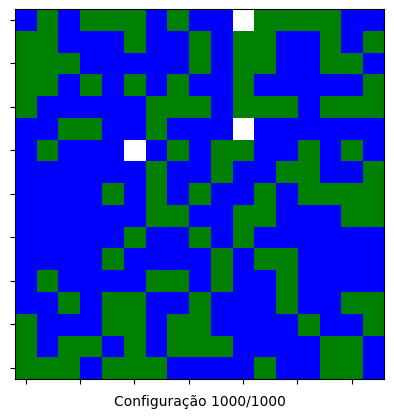

In [ ]:

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from matplotlib import colors

N_teste = 8  
M_teste = 6
tlimite_teste = 1000

matrices = simula(N_teste, M_teste, tlimite_teste)


# ---------------------------------------
# 2️⃣ Create Figure
# ---------------------------------------
frames=matrices
zvals=matrices[0]
cmap = colors.ListedColormap(['white', 'blue', 'green', 'yellow','orange','red','black'])
bounds=[0,1,2,3,4,5,6,7]
norm = colors.BoundaryNorm(bounds, cmap.N)

fig, ax = plt.subplots()
im = plt.imshow(frames[0], interpolation='nearest', origin='lower',
                    cmap=cmap, norm=norm)
#ax.set_title("Animating the Evolution")
ax.axes.xaxis.set_ticklabels([])
ax.axes.yaxis.set_ticklabels([])

#plt.savefig('confi0.png')
#plt.show()
# ---------------------------------------
# 3️⃣ Update Function
# ---------------------------------------
def update(frame_index):
    data = frames[frame_index]
    im.set_array(data)
    ax.set_xlabel(f"Configuração {frame_index + 1}/{len(frames)}")
    return [im]

# ---------------------------------------
# 4️⃣ Create and Display Animation
# ---------------------------------------
ani = FuncAnimation(
    fig,
    update,
    frames=len(frames),
    interval=400,  # milliseconds between frames
    blit=True,
    repeat=True
)

# Display inline in Jupyter
HTML(ani.to_jshtml())